In [1]:
%matplotlib inline
#matplotlib magic指令

import matplotlib
import matplotlib.pyplot as plt
from IPython import display
plt.rcParams.update({'font.size': 6})


# Simpsons Unlimited! 無限辛普森

To install trident, please cancel the syntax comment below.
安裝trident請取消下方語法註解

In [2]:
#!pip install tridentx 

引用相關軟體包，在此我們是透過環境變數TRIDENT_BACKEND='pytorch'來指定後台框架。

In [3]:
import os
os.environ['TRIDENT_BACKEND'] = 'pytorch'
#!pip install tridentx --upgrade
import trident as T
from trident import *
from trident import context
from trident.models.pytorch_gan import gan_builder
from trident.optims.trainers import GanTrainingPlan

trident 0.7.5


Using Pytorch backend.
Image Data Format: channels_first.
Image Channel Order: rgb.
Pytorch version:1.11.0+cu113.
Automatic Mixed Precision Support:False.


Opencv version:4.5.4-dev.
Pillow version:8.4.0.


## Preparation for data.準備數據 

In [4]:
#載入simpsons數據
data_provider=load_examples_data("simpsons")
print(data_provider.signature)

archive file is already existing, donnot need download again.
extraction is finished, donnot need extract again.
base_folder: C:/Users/allan/.trident/datasets/examples_simpsons/simpsons
get simpsons images :9876
data_provider( ) -> image: Tensor[(None, 200, 200, 3)] (ObjectType.rgb), noise: Tensor[(100,)] (ObjectType.random_noise) 


In [5]:


#加入數據增強
data_provider.image_transform_funcs=[
    OneOf(
        [Resize((64,64),True)],
        [Resize((72,72),True),
        RandomCrop((64,64))]
    ),
    RandomLighting(value_range=(0,0.8)),
    RandomAdjustGamma(gamma_range=(0.8,1.2)),
    RandomAdjustSaturation(scale=(0.8, 1.2)),
    RandomAdjustContrast(scale=(0.8 ,1.2)),
    Normalize(127.5,127.5)
]






We can use the preview_images command of the data provider to see what the data-enhanced image looks like .
我們可以利用資料提供者的preview_images指令來檢視數據增強後的圖片的樣子

image


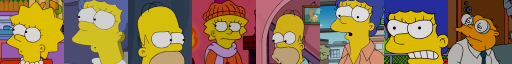

In [6]:
data_provider.preview_images()

In [7]:
_data,_noise=data_provider.next()
print(_data.shape)

(8, 3, 64, 64)


## Design network. 設計網路結構

In [8]:
#建構生成器以及鑑別器
generator, discriminator=gan_builder(noise_shape=100,input_shape=(3,64,64), generated_output_shape=(3,64,64), 
                upsample_mode= 'pixel_shuffle', generator_build_block='bottleneck', discriminator_build_block='bottleneck', 
                generator_network_type='decoder', discriminator_network_type='encoder',use_skip_connections=False,
                generator_use_spectral=True, discriminator_use_spectral=True, activation='selu', generator_norm='instance', discriminator_norm='batch',
                use_dilation=False, use_dropout=True, use_self_attention=True, use_minibatch_discrimination=False)


In [9]:
generator.with_optimizer(optimizer=Adam,lr=2e-4,betas=(0.5, 0.999),gradient_centalization='all')\
    .with_regularizer('l2') \
    .with_grad_clipping(3)\
    .with_automatic_mixed_precision_training()


automatic mixed precision training only enable when using pytorch 1.6 (or higher) as backend and cuda is available.


Model(
  (_regs): <function l2_reg at 0x0000017EA05B16A8>
)

In [10]:
discriminator.with_optimizer(optimizer=Adam,lr=5e-4,betas=(0.9, 0.999)) \
    .with_regularizer('l2')\
    .with_grad_clipping(3)\
    .with_automatic_mixed_precision_training()


automatic mixed precision training only enable when using pytorch 1.6 (or higher) as backend and cuda is available.


ImageClassificationModel(
  (_regs): <function l2_reg at 0x0000017EA05B16A8>
)

## Design TrainingPlan 設計學習計畫

為了能夠更簡單的訓練出穩定的GAN，因此trident特別設計了專門訓練GAN用的GanTrainingPlan。

In [11]:

plan=GanTrainingPlan()\
    .with_generator(generator)\
    .with_discriminator(discriminator)\
    .with_data_loader(data_provider)\
    .repeat_epochs(200)\
    .with_batch_size(32)\
    .with_gan_type('rasgan')\
    .with_noised_real_images(max_noise_intensity=0.12,decay=3000)\
    .with_feature_matching(loss_weight=0.5,start_epoch=3)\
    .with_total_variation_loss(start_epoch=10)\
    .with_ttur(multiplier=2.5)\
    .print_gpu_utilization(frequency=100,unit='batch')\
    .print_progress_scheduling(20, unit='batch') \
    .display_loss_metric_curve_scheduling(frequency=100, unit='batch', imshow=True) \
    .print_gradients_scheduling(100) \
    .save_model_scheduling(50, unit='batch')




g_loss( d_fake: Tensor[None] , d_real: Tensor[None] , real_label: Tensor[None] , fake_label: Tensor[None] ) -> output: Tensor[(None,)]  
real_loss( d_real: Tensor[None] , d_fake: Tensor[None] , real_label: Tensor[None] ) -> output: Tensor[(None,)]  
fake_loss( d_fake: Tensor[None] , d_real: Tensor[None] , fake_label: Tensor[None] ) -> output: Tensor[(None,)]  
dfake_logit( d_real: Tensor[None] , d_fake: Tensor[None] ) -> output: Tensor[(None,)]  
dfake_logit( d_real: Tensor[None] , d_fake: Tensor[None] ) -> output: Tensor[(None,)]  
dreal_logit( d_real: Tensor[None] , d_fake: Tensor[None] ) -> output: Tensor[(None,)]  
feature_matching( real_features: Tensor[None] , fake_features: Tensor[None] ) -> output: Tensor[(None,)]  



在開始執行前，我們可以利用Summary指令來檢視模型結構，其中因為我們指定的是LSGAN，為了讓他能夠更好的收斂，因此trident自動拿掉了鑑別器最後的sigmoid。

In [12]:
generator.summary()
#generator.model[9].dropout_rate=0.1

--------------------------------------------------------------------------------------------------------------------------------
                    Layer (type)                      Output Shape               Weight                             Bias      Param #   FLOPS #                  
0.module  [Dense]                                     [None, 4096]               'weight_u', [4096]                 'bias', [4096]  417,892  835,780  
                                                                                               'weight_v', [100]                                  
                                                                                               'weight_bar', [4096, 100]                          
0  [SpectralNorm]                                     [None, 4096]                                                            0  0  
1  [BatchNorm]                                        [None, 4096]               'weight', [4096]                   'bias', [4096] 

Model(
  (_losses): <function GanTrainingPlan.with_gan_type.<locals>.g_loss at 0x0000017EA3552048>
  (_losses): <function GanTrainingPlan.with_feature_matching.<locals>.feature_matching at 0x0000017EF4C2BF28>
  (_metrics): <function GanTrainingPlan.with_gan_type.<locals>.metric_dfake_logit at 0x0000017EA3536EA0>
  (loss_weights): 1.0
  (loss_weights): 0.5
  (_regs): <function l2_reg at 0x0000017EA05B16A8>
)

In [13]:
discriminator.summary()

#discriminator.model[11].dropout_rate=0.5

--------------------------------------------------------------------------------------------------------------------------------
                    Layer (type)                      Output Shape               Weight                              Bias      Param #   FLOPS #                  
0  [Conv2d]                                           [None, 32, 64, 64]         'weight', [32, 3, 5, 5]                       2,400  19,656,704  
1.conv.module  [Conv2d]                               [None, 64, 32, 32]         'weight_u', [64]                              18,784  38,466,560  
                                                                                                     'weight_v', [288]                                   
                                                                                                     'weight_bar', [64, 32, 3, 3]                        
1.conv  [SpectralNorm]                                [None, 64, 32, 32]                                 

ImageClassificationModel(
  (_losses): <function GanTrainingPlan.with_gan_type.<locals>.real_loss at 0x0000017EA3552268>
  (_losses): <function GanTrainingPlan.with_gan_type.<locals>.fake_loss at 0x0000017EA3536510>
  (_metrics): <function GanTrainingPlan.with_gan_type.<locals>.metric_dfake_logit at 0x0000017EA3536EA0>
  (_metrics): <function GanTrainingPlan.with_gan_type.<locals>.metric_dreal_logit at 0x0000017EA35522F0>
  (loss_weights): 1.0
  (loss_weights): 1.0
  (_regs): <function l2_reg at 0x0000017EA05B16A8>
)

is generator first: True
use label flipping: False
real_label 1
fake_label 0
generator data_feed:{ x: noise, img_fake: output, img_real: image, d_fake: d_fake, d_real: d_real, real_label: real_label, fake_label: fake_label, real_features: real_features, fake_features: fake_features }
discriminator data_feed:{ x: image, img_real: image, img_fake: img_fake, d_real: output, d_fake: d_fake, real_label: real_label, fake_label: fake_label }


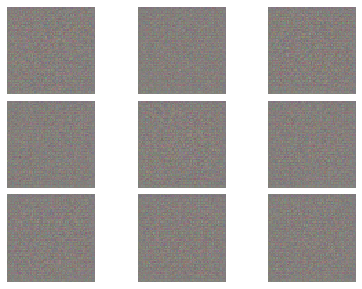

{ g_loss: 1.590, l2_reg_Loss: 0.006, total_losses: 1.596 }
{ real_loss: 0.789, fake_loss: 0.758, l2_reg_Loss: 0.003, total_losses: 1.549 }
 



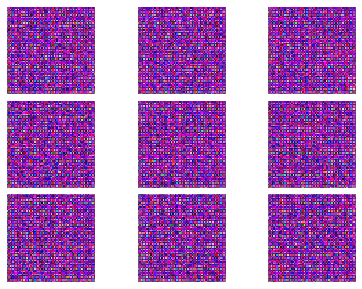

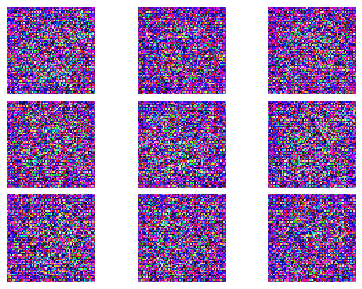

modelG  Step: 10s68ms  | Loss: 4.056 | dfake_logit: 38.468%  | lr: 2.000e-04  | epoch: 0  ( 21/309 )
modelD  Step: 2s696ms  | Loss: 1.737 | dfake_logit: 42.528% , dreal_logit: 62.780%  | lr: 5.000e-04  | epoch: 0  ( 21/309 )
 



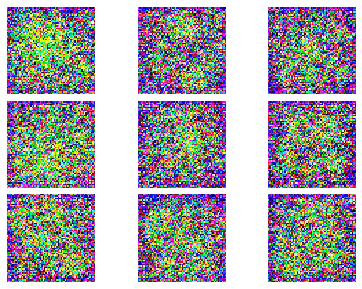

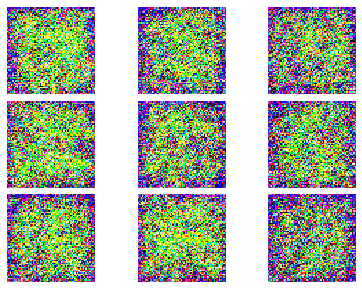

modelG  Step: 9s917ms  | Loss: 2.749 | dfake_logit: 57.606%  | lr: 2.000e-04  | epoch: 0  ( 41/309 )
modelD  Step: 2s619ms  | Loss: 2.609 | dfake_logit: 57.269% , dreal_logit: 49.445%  | lr: 5.000e-04  | epoch: 0  ( 41/309 )
 



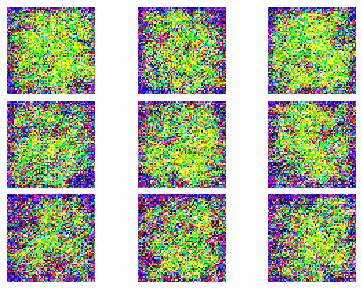

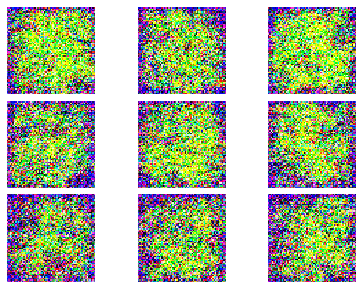

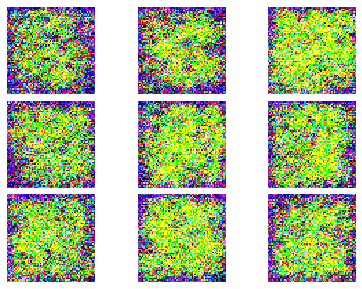

modelG  Step: 9s835ms  | Loss: 5.114 | dfake_logit: 50.006%  | lr: 2.000e-04  | epoch: 0  ( 61/309 )
modelD  Step: 2s758ms  | Loss: 4.600 | dfake_logit: 55.424% , dreal_logit: 58.319%  | lr: 5.000e-04  | epoch: 0  ( 61/309 )
 



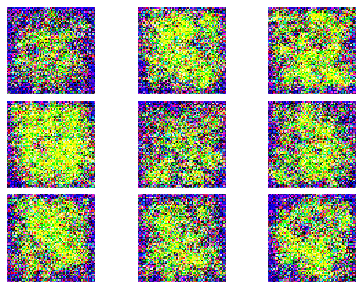

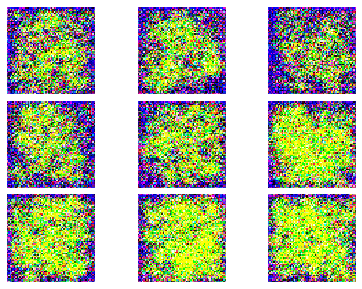

modelG  Step: 10s104ms | Loss: 5.800 | dfake_logit: 52.287%  | lr: 2.000e-04  | epoch: 0  ( 81/309 )
modelD  Step: 2s604ms  | Loss: 5.674 | dfake_logit: 50.375% , dreal_logit: 45.673%  | lr: 5.000e-04  | epoch: 0  ( 81/309 )
 



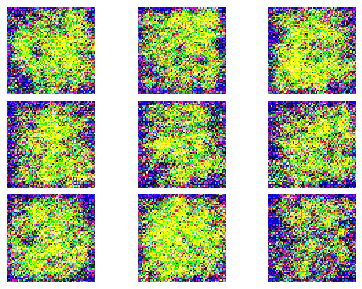

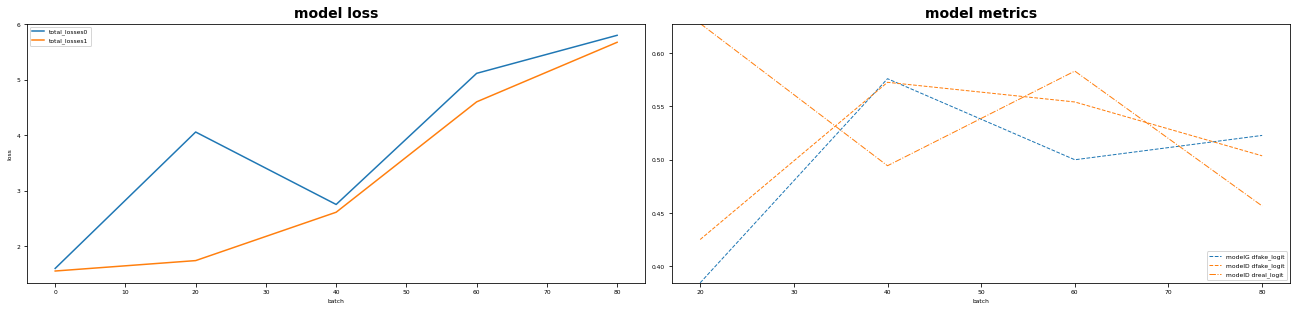

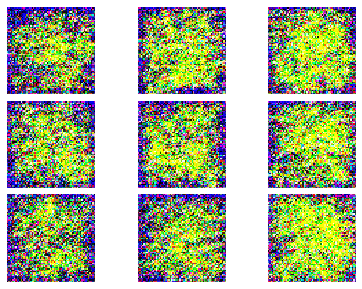

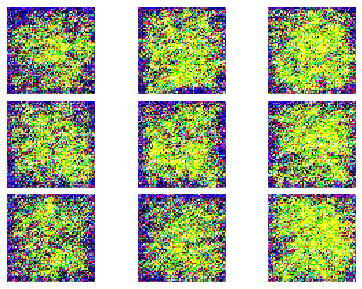

modelG          first_layer gradients: 9.472e-04 |last_layer gradients: 9.891e-03 

modelD          

modelG  Step: 12s570ms | Loss: 8.593 | dfake_logit: 57.755%  | lr: 2.000e-04  | epoch: 0  ( 101/309 )
modelD  Step: 3s284ms  | Loss: 8.686 | dfake_logit: 58.413% , dreal_logit: 36.969%  | lr: 5.000e-04  | epoch: 0  ( 101/309 )
 



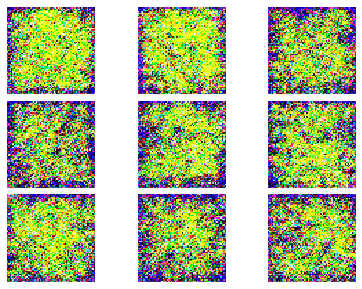

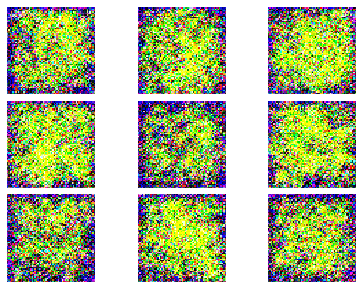

modelG  Step: 12s178ms | Loss: 8.569 | dfake_logit: 41.177%  | lr: 2.000e-04  | epoch: 0  ( 121/309 )
modelD  Step: 3s81ms   | Loss: 9.405 | dfake_logit: 49.350% , dreal_logit: 34.361%  | lr: 5.000e-04  | epoch: 0  ( 121/309 )
 



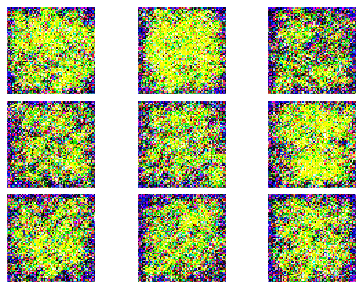

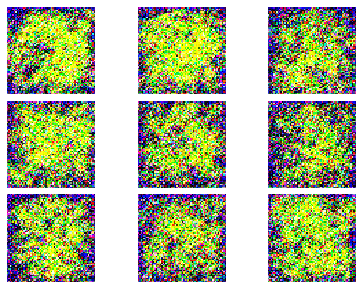

modelG  Step: 12s13ms  | Loss: 9.568 | dfake_logit: 36.144%  | lr: 2.000e-04  | epoch: 0  ( 141/309 )
modelD  Step: 3s244ms  | Loss: 9.512 | dfake_logit: 46.594% , dreal_logit: 64.586%  | lr: 5.000e-04  | epoch: 0  ( 141/309 )
 



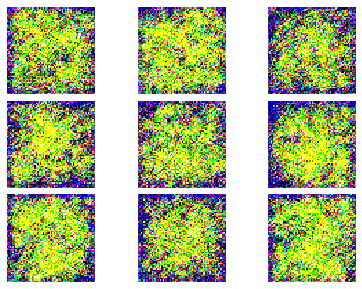

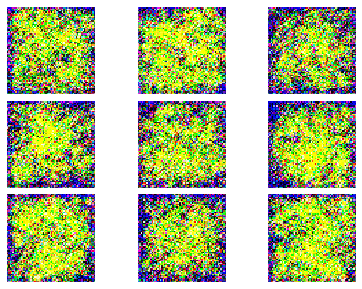

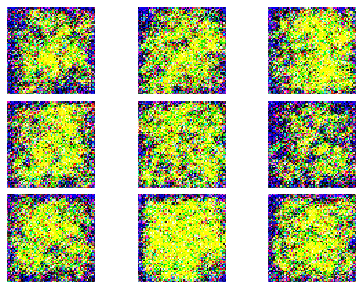

modelG  Step: 10s634ms | Loss: 9.755 | dfake_logit: 50.867%  | lr: 2.000e-04  | epoch: 0  ( 161/309 )
modelD  Step: 2s823ms  | Loss: 10.121 | dfake_logit: 33.821% , dreal_logit: 32.895%  | lr: 5.000e-04  | epoch: 0  ( 161/309 )
 



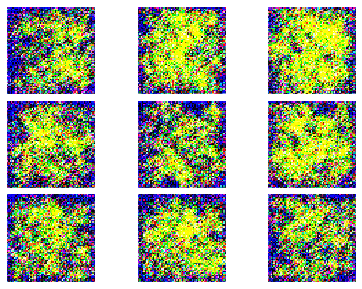

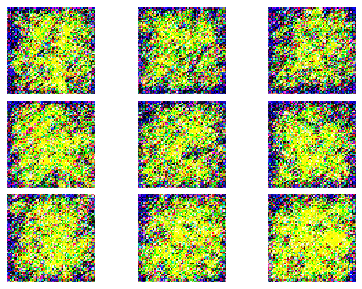

modelG  Step: 10s351ms | Loss: 10.722 | dfake_logit: 44.895%  | lr: 2.000e-04  | epoch: 0  ( 181/309 )
modelD  Step: 2s689ms  | Loss: 11.462 | dfake_logit: 60.382% , dreal_logit: 60.296%  | lr: 5.000e-04  | epoch: 0  ( 181/309 )
 



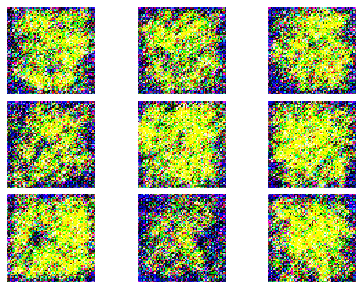

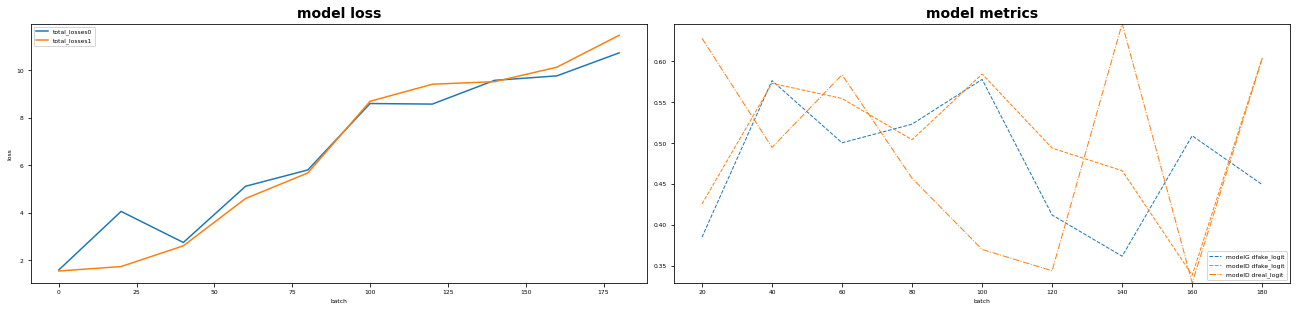

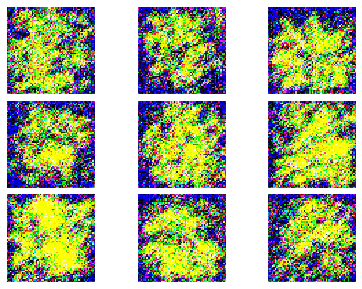

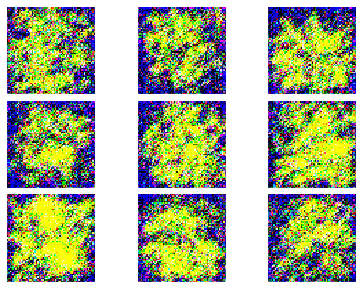

modelG          first_layer gradients: 1.061e-03 |last_layer gradients: 6.511e-03 

modelD          

modelG  Step: 14s35ms  | Loss: 15.241 | dfake_logit: 54.615%  | lr: 2.000e-04  | epoch: 0  ( 201/309 )
modelD  Step: 4s31ms   | Loss: 11.741 | dfake_logit: 62.263% , dreal_logit: 73.996%  | lr: 5.000e-04  | epoch: 0  ( 201/309 )
 



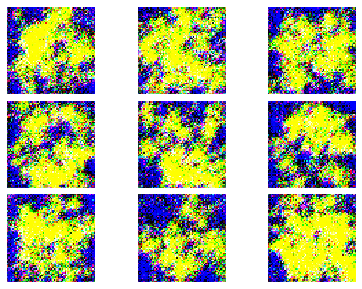

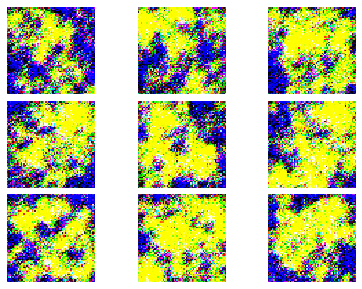

modelG  Step: 11s16ms  | Loss: 14.819 | dfake_logit: 75.011%  | lr: 2.000e-04  | epoch: 0  ( 221/309 )
modelD  Step: 3s       | Loss: 10.823 | dfake_logit: 69.699% , dreal_logit: 94.996%  | lr: 5.000e-04  | epoch: 0  ( 221/309 )
 



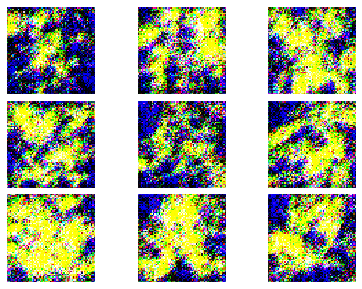

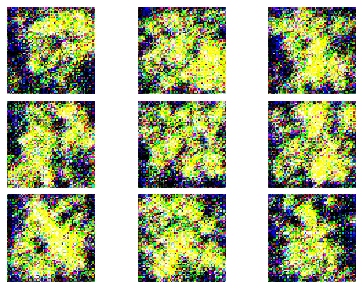

modelG  Step: 10s781ms | Loss: 12.087 | dfake_logit: 52.172%  | lr: 2.000e-04  | epoch: 0  ( 241/309 )
modelD  Step: 2s926ms  | Loss: 11.893 | dfake_logit: 68.548% , dreal_logit: 65.126%  | lr: 5.000e-04  | epoch: 0  ( 241/309 )
 



In [ ]:
plan.start_now()

Export model output history as GIF
將模型輸出歷程匯出為GIF

In [ ]:
from PIL import Image

files = glob.glob("Results/tile_image*.png")
print(len(files),flush=True)
_images = []
for n in tqdm(range(len(files))):
    f=files[n]
    _images.append(Image.open(f).convert('RGB'))

_images[0].save('Results/gan.gif', save_all=True, append_images=_images[1:], optimize=False, duration=2, loop=1)


Embed GIF in jupyter notebook
將GIF嵌入至jupyter notebook

In [ ]:
from IPython.display import HTML
HTML('<img src="Results/gan.gif">')